In [1]:
from pathlib import Path
import soundfile as sf

audio_file = Path.home() / ".cache/asr-study/zeroth/105_003_0029.flac"
sr = sf.info(audio_file).samplerate
chunk_size = round(0.2 * sr)

received = 0
for chunk in sf.blocks(audio_file, blocksize=chunk_size, dtype="float32"):
    received += len(chunk)
    print(f"이번 조각: {len(chunk)}개 | 지금까지 들어온 음성: {received / sr:.2f}초")

이번 조각: 3200개 | 지금까지 들어온 음성: 0.20초
이번 조각: 3200개 | 지금까지 들어온 음성: 0.40초
이번 조각: 3200개 | 지금까지 들어온 음성: 0.60초
이번 조각: 3200개 | 지금까지 들어온 음성: 0.80초
이번 조각: 3200개 | 지금까지 들어온 음성: 1.00초
이번 조각: 3200개 | 지금까지 들어온 음성: 1.20초
이번 조각: 3200개 | 지금까지 들어온 음성: 1.40초
이번 조각: 3200개 | 지금까지 들어온 음성: 1.60초
이번 조각: 3200개 | 지금까지 들어온 음성: 1.80초
이번 조각: 3200개 | 지금까지 들어온 음성: 2.00초
이번 조각: 3200개 | 지금까지 들어온 음성: 2.20초
이번 조각: 3200개 | 지금까지 들어온 음성: 2.40초
이번 조각: 3200개 | 지금까지 들어온 음성: 2.60초
이번 조각: 3200개 | 지금까지 들어온 음성: 2.80초
이번 조각: 3200개 | 지금까지 들어온 음성: 3.00초
이번 조각: 3200개 | 지금까지 들어온 음성: 3.20초
이번 조각: 3200개 | 지금까지 들어온 음성: 3.40초
이번 조각: 3200개 | 지금까지 들어온 음성: 3.60초
이번 조각: 3200개 | 지금까지 들어온 음성: 3.80초
이번 조각: 3200개 | 지금까지 들어온 음성: 4.00초
이번 조각: 3200개 | 지금까지 들어온 음성: 4.20초
이번 조각: 3200개 | 지금까지 들어온 음성: 4.40초
이번 조각: 3200개 | 지금까지 들어온 음성: 4.60초
이번 조각: 3200개 | 지금까지 들어온 음성: 4.80초
이번 조각: 3200개 | 지금까지 들어온 음성: 5.00초
이번 조각: 3200개 | 지금까지 들어온 음성: 5.20초
이번 조각: 3200개 | 지금까지 들어온 음성: 5.40초
이번 조각: 3200개 | 지금까지 들어온 음성: 5.60초
이번 조각: 3200개 | 지금까지 들어온 음성: 5.80초
이번 조각: 3200개 |

In [2]:
import numpy as np
import sherpa_onnx

model_dir = Path.home() / ".cache/asr-study/streaming-zipformer-ko"

online = sherpa_onnx.OnlineRecognizer.from_transducer(
    encoder=str(model_dir / "encoder.int8.onnx"),  # 지금까지 들어온 소리의 특징을 읽어요.
    decoder=str(model_dir / "decoder.onnx"),      # 앞에서 고른 글자 조각을 살펴봐요.
    joiner=str(model_dir / "joiner.int8.onnx"),   # 두 정보를 합쳐 다음 글자 조각을 고를지 판단해요.
    tokens=str(model_dir / "tokens.txt"),         # 모델이 쓰는 번호에 해당하는 글자 조각을 찾아요.
)

In [3]:
stream = online.create_stream()  # 이 녹음 한 편에 쓸 받아쓰기 공책을 열어요.
received = 0                    # 지금까지 보낸 실제 음성 샘플 수예요.
previous = ""                   # 직전에 화면에 보여준 문장이에요.
gain = 3.0                      # 이번 녹음의 입력 볼륨을 3배로 해요.

def read_text(stream):
    while online.is_ready(stream):        # 처리할 만큼 소리가 모였으면
        online.decode_stream(stream)      # 모인 소리로 받아쓰기를 한 단계 진행해요.
    return online.get_result(stream).strip()  # 지금까지 받아쓴 문장을 돌려줘요.

for chunk in sf.blocks(audio_file, blocksize=chunk_size, dtype="float32"):
    stream.accept_waveform(sr, chunk * gain)  # 이번 0.2초 조각을 같은 공책에 넣어요.
    received += len(chunk)                    # 마지막 856개도 실제 개수만큼 더해요.
    text = read_text(stream)                  # 여기까지 듣고 나온 문장을 확인해요.

    if text != previous:                      # 직전 문장과 달라졌을 때만
        print(f"{received / sr:.2f}초 | {text}")
        previous = text                       # 다음 조각과 비교할 수 있게 기억해요.

stream.accept_waveform(sr, np.zeros(int(0.66 * sr), dtype="float32"))
stream.input_finished()
print("최종 문장 |", read_text(stream))

1.40초 | 뭔
1.80초 | 뭔 떡인지
4.60초 | 뭔 떡인지 못 받고
5.40초 | 뭔 떡인지 못 받고 그냥
6.20초 | 뭔 떡인지 못 받고 그냥 심각
6.60초 | 뭔 떡인지 못 받고 그냥 심각한 결과
8.80초 | 뭔 떡인지 못 받고 그냥 심각한 결과를
9.20초 | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다
9.40초 | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.
최종 문장 | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.


In [4]:
gain = 3.0        # 지난 실험과 같은 볼륨을 써요.
final_texts = {}  # 조각 길이별로 최종 문장을 저장할 빈 공간이에요.

for seconds in [0.1, 0.2, 0.4]:
    stream = online.create_stream()    # 실험마다 새 받아쓰기 공책을 열어요.
    block_size = round(seconds * sr)   # 이번 조각 하나에 넣을 샘플 수예요.
    received = 0                       # 지금까지 보낸 샘플 수예요.
    first_time = None                  # 아직 첫 글자가 나온 시간이 없다는 뜻이에요.

    chunks = sf.blocks(audio_file, blocksize=block_size, dtype="float32")

    for number, chunk in enumerate(chunks, start=1):
        stream.accept_waveform(sr, chunk * gain)  # 이번 조각을 보내요.
        received += len(chunk)                    # 실제로 보낸 샘플 수를 더해요.
        text = read_text(stream)                  # 여기까지 들은 내용을 받아써요.

        if first_time is None and text:
            first_time = received / sr            # 첫 글자를 봤을 때 딱 한 번 기록해요.

    # 여기부터는 파일의 마지막 조각까지 보낸 뒤에 실행돼요.
    silence = np.zeros(round(0.66 * sr), dtype="float32")
    stream.accept_waveform(sr, silence)           # 끝소리까지 처리할 여유를 줘요.
    stream.input_finished()                       # 더 들어올 소리가 없다고 알려요.
    final_texts[seconds] = read_text(stream)       # 남은 계산을 마치고 최종 문장을 저장해요.

    print(f"{seconds}초씩 | 첫 출력 {first_time}초 | 총 {number}조각")
    print(final_texts[seconds])

print("세 문장이 모두 같은가?", final_texts[0.1] == final_texts[0.2] == final_texts[0.4])

0.1초씩 | 첫 출력 1.4초 | 총 105조각
뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.
0.2초씩 | 첫 출력 1.4초 | 총 53조각
뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.
0.4초씩 | 첫 출력 1.6초 | 총 27조각
뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.
세 문장이 모두 같은가? True


In [5]:
def describe_change(previous, current):
    if current.startswith(previous):       # 앞에서 쓴 문장이 그대로 남아 있나요?
        added = current[len(previous):]    # 그 뒤에 새로 붙은 부분만 꺼내요.
        return f"추가 {added!r}"
    return f"수정 {previous!r} → {current!r}"  # 앞부분까지 달라졌다면 수정으로 표시해요.


gain = 3.0  # 지난 실습과 같은 볼륨이에요.

for seconds in [0.1, 0.2, 0.4]:
    print(f"\n[{seconds}초씩 넣기]")
    stream = online.create_stream()       # 조각 길이를 바꿀 때마다 새 공책을 열어요.
    block_size = round(seconds * sr)      # 조각 하나에 담을 샘플 수예요.
    received = 0                          # 지금까지 보낸 샘플 수예요.
    previous = ""                         # 처음에는 공책에 적힌 글자가 없어요.

    chunks = sf.blocks(audio_file, blocksize=block_size, dtype="float32")
    for chunk in chunks:
        stream.accept_waveform(sr, chunk * gain)   # 이번 조각을 보내요.
        received += len(chunk)                     # 보낸 샘플 수를 더해요.
        current = read_text(stream)                # 지금 공책에 적힌 문장을 읽어요.

        if current != previous:                    # 직전 문장과 달라졌을 때만
            change = describe_change(previous, current)
            print(f"{received / sr:.2f}초 | {change} | {current}")
            previous = current                     # 다음 비교를 위해 지금 문장을 기억해요.

    silence = np.zeros(round(0.66 * sr), dtype="float32")
    stream.accept_waveform(sr, silence)             # 녹음의 끝부분까지 처리하게 해요.
    stream.input_finished()                        # 더 들어올 소리가 없다고 알려줘요.
    final = read_text(stream)
    if final != previous:
        print("마무리 |", describe_change(previous, final))
    print("최종 문장 |", final)


[0.1초씩 넣기]
1.40초 | 추가 '뭔' | 뭔
1.70초 | 추가 ' 떡인지' | 뭔 떡인지
4.60초 | 추가 ' 못 받고' | 뭔 떡인지 못 받고
5.30초 | 추가 ' 그냥' | 뭔 떡인지 못 받고 그냥
6.20초 | 추가 ' 심각' | 뭔 떡인지 못 받고 그냥 심각
6.50초 | 추가 '한 결과' | 뭔 떡인지 못 받고 그냥 심각한 결과
8.80초 | 추가 '를' | 뭔 떡인지 못 받고 그냥 심각한 결과를
9.10초 | 추가 ' 내렸습니다' | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다
9.40초 | 추가 '.' | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.
최종 문장 | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.

[0.2초씩 넣기]
1.40초 | 추가 '뭔' | 뭔
1.80초 | 추가 ' 떡인지' | 뭔 떡인지
4.60초 | 추가 ' 못 받고' | 뭔 떡인지 못 받고
5.40초 | 추가 ' 그냥' | 뭔 떡인지 못 받고 그냥
6.20초 | 추가 ' 심각' | 뭔 떡인지 못 받고 그냥 심각
6.60초 | 추가 '한 결과' | 뭔 떡인지 못 받고 그냥 심각한 결과
8.80초 | 추가 '를' | 뭔 떡인지 못 받고 그냥 심각한 결과를
9.20초 | 추가 ' 내렸습니다' | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다
9.40초 | 추가 '.' | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.
최종 문장 | 뭔 떡인지 못 받고 그냥 심각한 결과를 내렸습니다.

[0.4초씩 넣기]
1.60초 | 추가 '뭔' | 뭔
2.00초 | 추가 ' 떡인지' | 뭔 떡인지
4.80초 | 추가 ' 못 받고' | 뭔 떡인지 못 받고
5.60초 | 추가 ' 그냥' | 뭔 떡인지 못 받고 그냥
6.40초 | 추가 ' 심각' | 뭔 떡인지 못 받고 그냥 심각
6.80초 | 추가 '한 결과' | 뭔 떡인지 못 받고 그냥 심각한 결과
8.80초 | 추가 '를' | 뭔 떡인지 못 받고 그냥 심각한 결과를
9.20초 | 추가 ' 내렸습니다' 

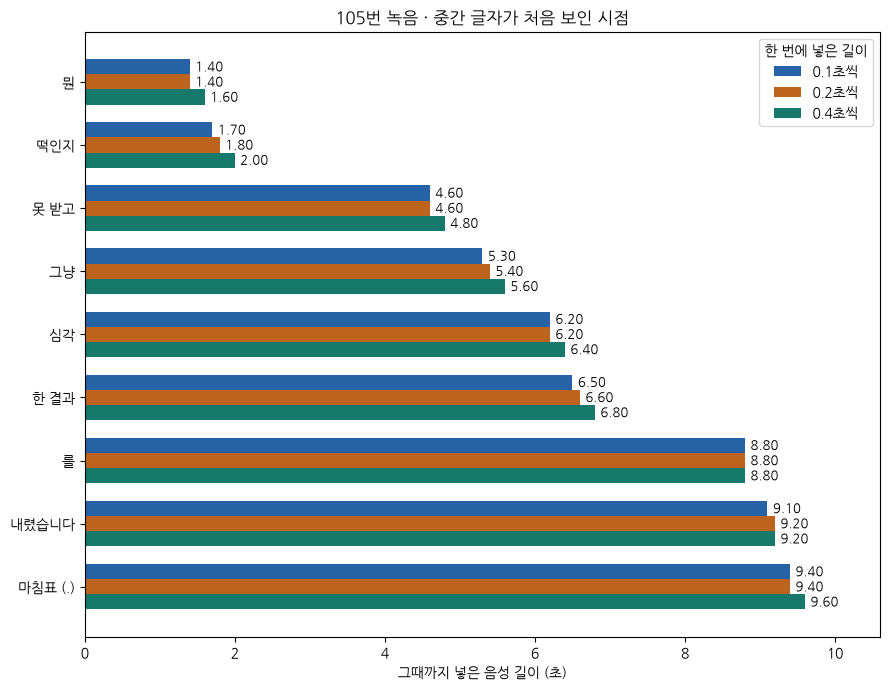

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "NanumGothic"  # 그래프에서 한글을 보여줘요.

# 화면에 새로 붙은 글자를 순서대로 적어요.
parts = ["뭔", "떡인지", "못 받고", "그냥", "심각", "한 결과", "를", "내렸습니다", "마침표 (.)"]

# 위 글자들이 각각 처음 보인 시간이에요.
times_01 = [1.40, 1.70, 4.60, 5.30, 6.20, 6.50, 8.80, 9.10, 9.40]
times_02 = [1.40, 1.80, 4.60, 5.40, 6.20, 6.60, 8.80, 9.20, 9.40]
times_04 = [1.60, 2.00, 4.80, 5.60, 6.40, 6.80, 8.80, 9.20, 9.60]

y = np.arange(len(parts))  # 글자 묶음 9개가 들어갈 자리를 만들어요.
h = 0.24                   # 막대 하나의 두께예요.
fig, ax = plt.subplots(figsize=(9, 7))

# 같은 글자의 막대 세 개를 위·가운데·아래에 나란히 그려요.
bars_01 = ax.barh(y - h, times_01, height=h, color="#2563A6", label="0.1초씩")
bars_02 = ax.barh(y,     times_02, height=h, color="#BE631E", label="0.2초씩")
bars_04 = ax.barh(y + h, times_04, height=h, color="#17796B", label="0.4초씩")

for bars in [bars_01, bars_02, bars_04]:
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)  # 막대 끝에 시간을 적어요.

ax.set_yticks(y, labels=parts)  # 왼쪽에 글자를 표시해요.
ax.invert_yaxis()               # 처음 나온 ‘뭔’을 맨 위에 놓아요.
ax.set_xlim(0, 10.6)
ax.set_xlabel("그때까지 넣은 음성 길이 (초)")
ax.set_title("105번 녹음 · 중간 글자가 처음 보인 시점")
ax.legend(title="한 번에 넣은 길이", loc="upper right")
fig.tight_layout()
plt.show()